In [10]:
import numpy as np

import ngsolve 
from ngsolve.webgui import Draw
import netgen.geom2d

import math
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import importlib
import copy # for copying objects (like meshes!)
%matplotlib inline

import cgle  # many subroutines moved here 

notebookroot = 'CGLE_rect_v00_'  # notebook name for file names 

# some globals

# for figures
labelpos = [0.03,0.98] 
figsize=(7,2.5)  
cbar_shrink = 0.4
figparms = ['',labelpos,figsize,cbar_shrink]

dt = 0.05  # timestep
korder=3  # order for finite elements
bndlist0 = 'p1_bottom_left|p1_bottom_right'  # list of boundaries for Dirichlet boundary conditions

In [12]:
importlib.reload(cgle)  # if you are working on the helper routines 

<module 'cgle' from '/Users/aquillen/Desktop/summer25/pylab/Boundaries_F2026/cgle.py'>

### The complex Ginzburg-Landau model with fixed BC Dirichlet, left-right sign difference on boundary 

In [11]:
# routine to set Dirichlet boundaries
# with a single free parameter.  
# Real parts of left and right boundary are set to have opposite sign
# Imaginary parts are set to 0 
# names of boundaries are fixed! 
# arguments:  
#   fes: finite element system
#   mesh: mesh
#   bl_real: real parameter 
# returns a gridfunction on finite element system with boundary set 
def mkbnd_lr(fes,mesh,bl_real=-1.2):
    bl_imag = 0; br_imag = 0
    br_real = -bl_real
    gfu_bnd = ngsolve.GridFunction(fes) 
    bdry_values_real = {'p1_bottom_left': bl_real, 'p1_bottom_right': br_real} 
    bdry_values_imag = {'p1_bottom_left': bl_imag, 'p1_bottom_right': br_imag} 

    cf_real  = mesh.BoundaryCF(bdry_values_real, default=0)  # coefficient function 
    cf_imag  = mesh.BoundaryCF(bdry_values_imag, default=0)
    gfu_bnd = ngsolve.GridFunction(fes) 
    gfu_bnd.components[0].Set(cf_real,definedon=mesh.Boundaries('p1_bottom_left|p1_bottom_right')) 
    gfu_bnd.components[1].Set(cf_imag,definedon=mesh.Boundaries('p1_bottom_left|p1_bottom_right')) 
    return gfu_bnd

# routine to set Dirichlet boundaries
# for exploring different phase differences on either side of origin on lower boundary
# arguments:  
#   fes: finite element system
#   mesh: mesh
#   amp, phifac: real parameters
# returns a gridfunction on finite element system with boundary set 
def mkbnd_phase(fes,mesh,amp=2,phi1fac=0.5):
    phi1 = phi1fac*np.pi  # best at pi/2 with phi1fac=0.5
    phi2 = -phi1
    cphi1 = np.cos(phi1); sphi1 = np.sin(phi1)
    cphi2 = np.cos(phi2); sphi2 = np.sin(phi2)
    # if phi1 = pi/2 then cphi1 = 1, cphi2 = -1, sphi1=sphi2=0
    #amp = 2
    bl_real = amp*cphi1
    bl_imag = amp*sphi1
    br_real = amp*cphi2
    br_imag = amp*sphi2
    print('bndvals: Left: {:.1f}+ j {:.1f} Right = {:.1f}+ j {:.1f}'.format(bl_real,bl_imag,br_real,br_imag))  # !!!!
    
    #slope = ngsolve.x/40 
    gfu_bnd = ngsolve.GridFunction(fes) 
    bdry_values_real = {'p1_bottom_left': bl_real, 'p1_bottom_right': br_real} #  'p1_left': l_real,'p1_right': r_real}
    bdry_values_imag = {'p1_bottom_left': bl_imag, 'p1_bottom_right': br_imag} #  'p1_left': l_imag,'p1_right': r_imag}

    cf_real  = mesh.BoundaryCF(bdry_values_real, default=0)
    cf_imag  = mesh.BoundaryCF(bdry_values_imag, default=0)
    gfu_bnd = ngsolve.GridFunction(fes) 
    gfu_bnd.components[0].Set(cf_real,definedon=mesh.Boundaries('p1_bottom_left|p1_bottom_right')) 
    gfu_bnd.components[1].Set(cf_imag,definedon=mesh.Boundaries('p1_bottom_left|p1_bottom_right')) 
    return gfu_bnd

('p1_bottom_left', 'p1_bottom_right', 'p1_right', 'p1_top', 'p1_left')


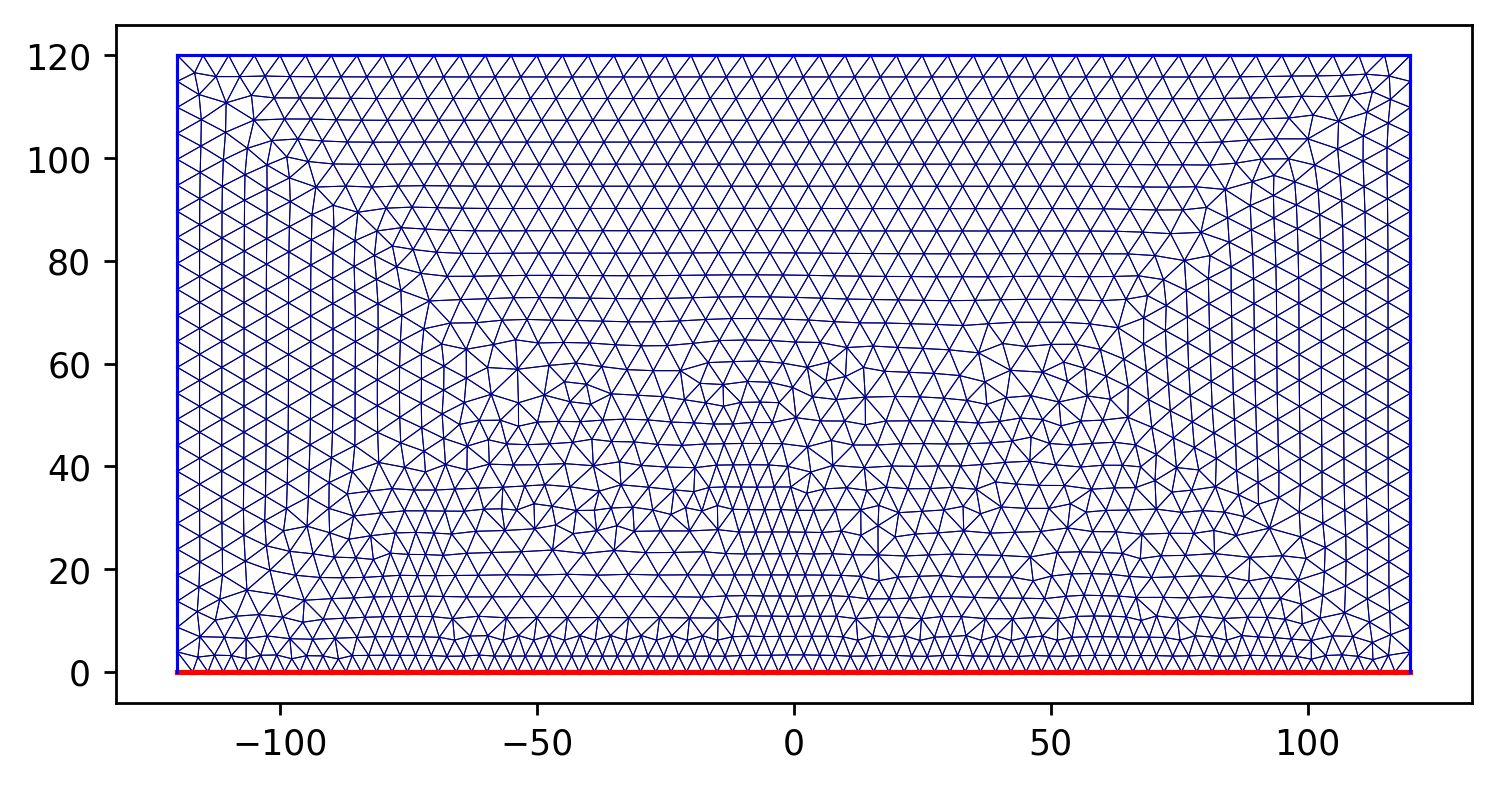

In [12]:
# create domain
geo = netgen.geom2d.CSG2d()

# create a rectangle 
fac=2
hx = 120.0*fac
hy = 60.0*fac
zlow = 0
poly1 = netgen.geom2d.Solid2d( [
    (0,0),
    netgen.geom2d.EdgeInfo(bc="p1_bottom_left",maxh=1.5*fac), # set bc name for segment (0,0)-(hx/2,0)
    (hx/2,zlow),
    netgen.geom2d.EdgeInfo(bc="p1_bottom_right",maxh=1.5*fac), # set bc name for segment (0,0)-(hx,0)
    (hx,0),
    netgen.geom2d.EdgeInfo(bc="p1_right"),  # set bc for segment (hx,0)-(hx,hy)
    (hx,hy),
    netgen.geom2d.EdgeInfo(bc="p1_top"),  # set bc for segment (hx,hy)-(0,hy)
    (0,hy),
    netgen.geom2d.EdgeInfo(bc="p1_left"), # set bc for segment (0,hy)-(0,0)
    ] )
poly1.Move((-hx/2,0))  # center the rectangle in x but not y
geo.Add(poly1)

maxhval = 2.5*fac
mesh = ngsolve.Mesh(geo.GenerateMesh(maxh=maxhval))
print(mesh.GetBoundaries())

ofile = notebookroot+'mesh.png'
cgle.draw_mesh(mesh,ofile=ofile,figsize=(7,4),d_boundaries='p1_bottom_left|p1_bottom_right',n_boundaries='p1_top|p1_right|p1_left')

In [13]:

fes = cgle.mkfes(mesh,korder,bndlist0) # make finite element system, with Dirichlet boundary 
gfu = ngsolve.GridFunction(fes) # make the field to hold the solution 

gfu_bnd = mkbnd_lr(fes,mesh,bl_real=-2)  # set boundary 

sig = 0.01 # noise level
cgle.gen_init(gfu,mesh,0,sig,maxhval,A_r0=0.9,A_i0=0)  # generate interior initial conditions gen_init(gfu,mesh,nseeds,sig,hseeds):
# the A_r0, A_i0 are the mean initial field value 

cgle.set_on_boundary(gfu,gfu_bnd,fes) # update all dirichlet boundaries on gfu using gfu_bnd
scene=Draw(cgle.norm_gfu(gfu),mesh, min=0,max=1.2,\
           settings = {  "Colormap" : { "ncolors" : 20 } , "Objects" : {"Wireframe" : False}})

time = 0.0

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Colormap': {'ncolors': 20}, …

In [14]:
alpha = 4; beta = 0.1 # choose CGLE parameters, Aranson form of CGLE PDE
clabel = r'$\alpha=${:.1f}, '.format(alpha) + r'$\beta=${:.1f}'.format(beta) 
figparms[0] = clabel
invastar, a_lap, b_op, minv  = cgle.mk_ops(fes,alpha,dt)  # construct operators 
ofileroot = notebookroot+'_a1_'
cgle.Aranson_to_Chate(alpha,beta)
time = cgle.TimeStepping_CN(fes,gfu,scene,invastar,a_lap,minv,beta,dt,t0=time,tdur=200,nsamples=200,gfun_op = True,uform='Aran',\
                         poutput=True,ofileroot=ofileroot,figparms=figparms)

# I made a movie of this, used movie to measure defect speed 

 b_1=-4.00 b_3 =10.00
craete bilinearformapplication
 1.000  CGLE_rect_v00__a1_000.png
 2.050  CGLE_rect_v00__a1_001.png
 3.100  CGLE_rect_v00__a1_002.png
 4.150  CGLE_rect_v00__a1_003.png
 5.200  CGLE_rect_v00__a1_004.png
 6.250  CGLE_rect_v00__a1_005.png
 7.300  CGLE_rect_v00__a1_006.png
 8.350  CGLE_rect_v00__a1_007.png
 9.400  CGLE_rect_v00__a1_008.png
 10.450  CGLE_rect_v00__a1_009.png
 11.500  CGLE_rect_v00__a1_010.png
 12.550  CGLE_rect_v00__a1_011.png
 13.600  CGLE_rect_v00__a1_012.png
 14.650  CGLE_rect_v00__a1_013.png
 15.700  CGLE_rect_v00__a1_014.png
 16.750  CGLE_rect_v00__a1_015.png
 17.800  CGLE_rect_v00__a1_016.png
 18.850  CGLE_rect_v00__a1_017.png
 19.900  CGLE_rect_v00__a1_018.png
 20.950  CGLE_rect_v00__a1_019.png
 22.000  CGLE_rect_v00__a1_020.png
 23.050  CGLE_rect_v00__a1_021.png
 24.100  CGLE_rect_v00__a1_022.png
 25.150  CGLE_rect_v00__a1_023.png
 26.200  CGLE_rect_v00__a1_024.png
 27.250  CGLE_rect_v00__a1_025.png
 28.300  CGLE_rect_v00__a1_026.png
 29.350  CG

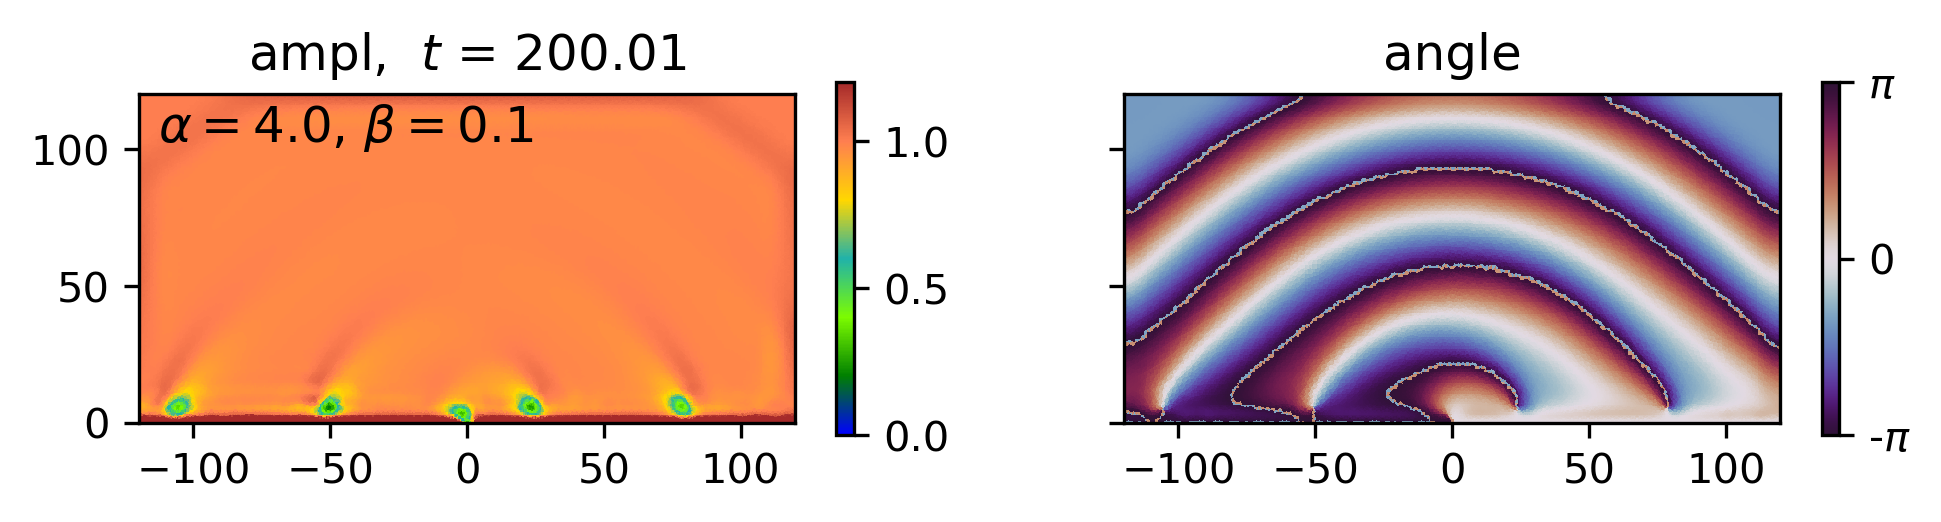

In [104]:
#importlib.reload(cgle)  # if you are working on the helper routines 
ofile = ofileroot + '_snap.png'
cgle.disp(mesh,gfu,time,ofile=ofile,draw_mesh=False,subdivn=2,figsize=[7,3],label=clabel,labelpos=[0.03,0.98],cbar_shrink=0.4) 
cgle.disp(mesh,gfu,time,ofile="",draw_mesh=False,subdivn=2,figsize=[7,3],label=clabel,labelpos=[0.03,0.98],cbar_shrink=0.4) 

In [50]:
fes = cgle.mkfes(mesh,korder,bndlist0) # make finite element system, with Dirichlet boundary 
gfu = ngsolve.GridFunction(fes) # make the field to hold the solution 

gfu_bnd = mkbnd_lr(fes,mesh,bl_real=-2)  # set boundary 

sig = 0.01 # noise level
cgle.gen_init(gfu,mesh,0,sig,maxhval,A_r0=0.9,A_i0=0)  # generate interior initial conditions gen_init(gfu,mesh,nseeds,sig,hseeds):
# the A_r0, A_i0 are the mean initial field value 

cgle.set_on_boundary(gfu,gfu_bnd,fes) # update all dirichlet boundaries on gfu using gfu_bnd
scene=Draw(cgle.norm_gfu(gfu),mesh, min=0,max=1.2,\
           settings = {  "Colormap" : { "ncolors" : 20 } , "Objects" : {"Wireframe" : False}})

time = 0.0

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Colormap': {'ncolors': 20}, …

In [ ]:
alpha = 2; beta = 0.1 # choose CGLE parameters, Aranson form of CGLE PDE
clabel = r'$\alpha=${:.1f}, '.format(alpha) + r'$\beta=${:.1f}'.format(beta) 
figparms[0] = clabel
invastar, a_lap, b_op, minv  = cgle.mk_ops(fes,alpha,dt)  # construct operators 
ofileroot = notebookroot+'_a2_'
cgle.Aranson_to_Chate(alpha,beta)
time = cgle.TimeStepping_CN(fes,gfu,scene,invastar,a_lap,minv,beta,dt,t0=time,tdur=400,nsamples=200,gfun_op = True,uform='Aran',\
                         poutput=True,ofileroot=ofileroot,figparms=figparms)


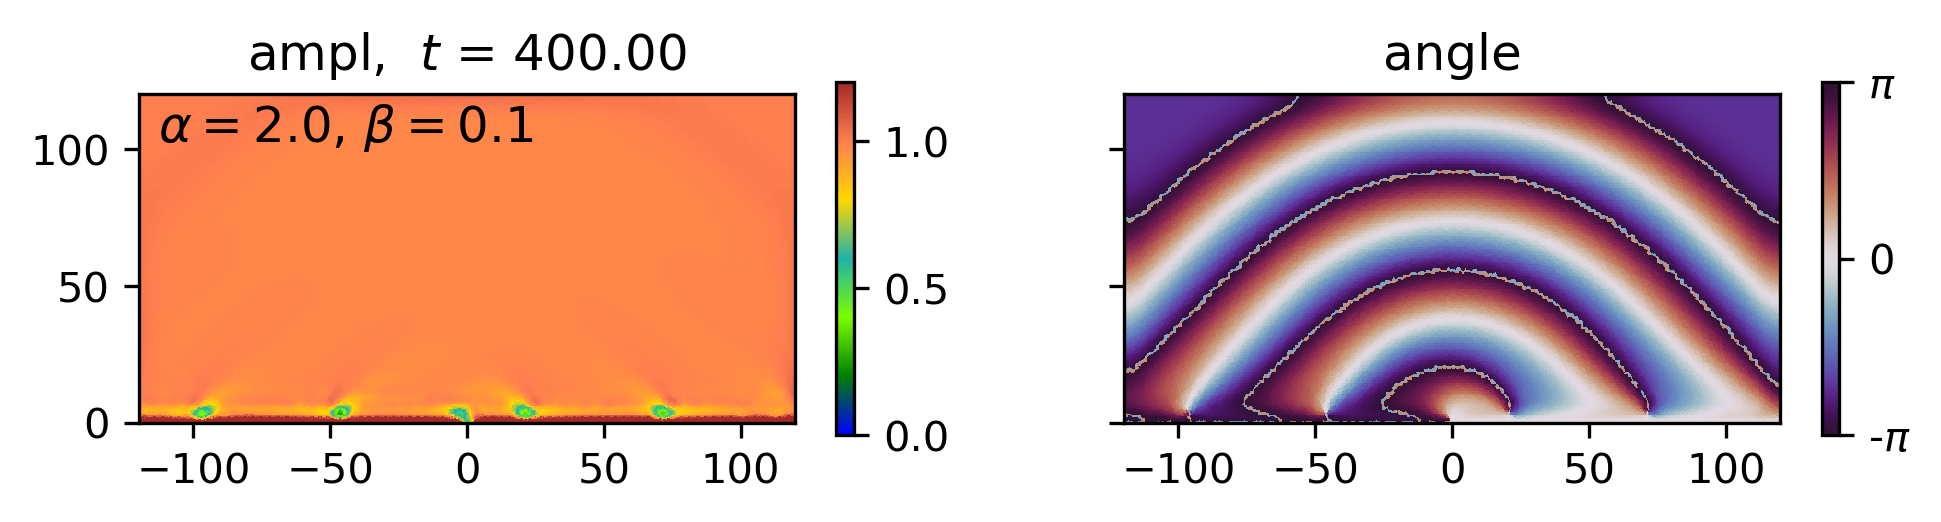

In [26]:
# had to run it to 400
#importlib.reload(cgle)  # if you are working on the helper routines 
ofile = ofileroot + '_snap.png'
cgle.disp(mesh,gfu,time,ofile=ofile,draw_mesh=False,subdivn=2,figsize=[7,3],label=clabel,labelpos=[0.03,0.98],cbar_shrink=0.4) 
cgle.disp(mesh,gfu,time,ofile="",draw_mesh=False,subdivn=2,figsize=[7,3],label=clabel,labelpos=[0.03,0.98],cbar_shrink=0.4) 

craete bilinearformapplication
 449.950

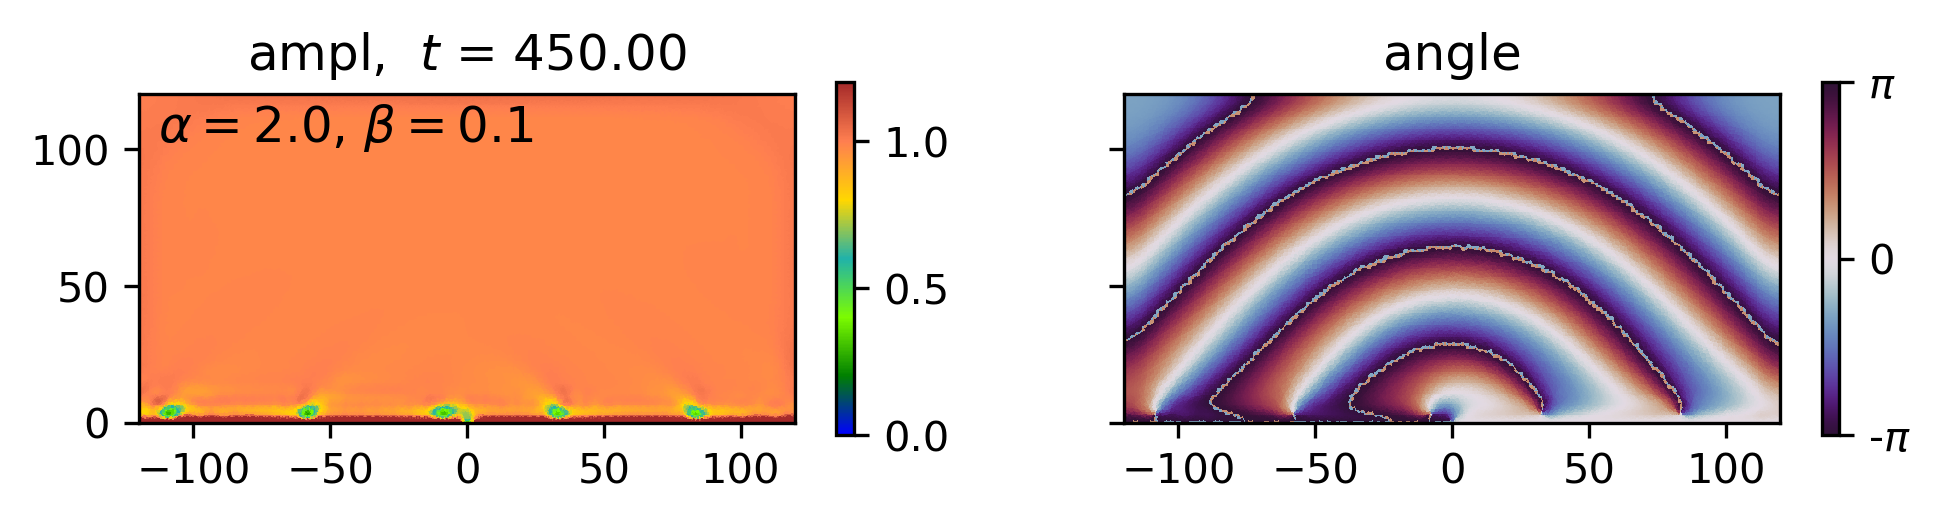

In [27]:
# run for 50 more to measure defect speed 
time = cgle.TimeStepping_CN(fes,gfu,scene,invastar,a_lap,minv,beta,dt,t0=time,tdur=50,nsamples=50,gfun_op = True,uform='Aran',\
                         poutput=False,ofileroot=ofileroot,figparms=figparms)

# had to run it to 400
#importlib.reload(cgle)  # if you are working on the helper routines 
ofile = ofileroot + '_snap2.png'
cgle.disp(mesh,gfu,time,ofile=ofile,draw_mesh=False,subdivn=2,figsize=[7,3],label=clabel,labelpos=[0.03,0.98],cbar_shrink=0.4) 
cgle.disp(mesh,gfu,time,ofile="",draw_mesh=False,subdivn=2,figsize=[7,3],label=clabel,labelpos=[0.03,0.98],cbar_shrink=0.4) 

In [42]:
fes = cgle.mkfes(mesh,korder,bndlist0) # make finite element system, with Dirichlet boundary 
gfu = ngsolve.GridFunction(fes) # make the field to hold the solution 
gfu_bnd = mkbnd_lr(fes,mesh,bl_real=-1.0)

sig = 0.01
cgle.gen_init(gfu,mesh,0,sig,maxhval,A_r0=0.9,A_i0=0)  # generate interior initial conditions gen_init(gfu,mesh,nseeds,sig,hseeds):

cgle.set_on_boundary(gfu,gfu_bnd,fes) # update all dirichlet boundaries on gfu using gfu_bnd
scene=Draw(cgle.norm_gfu(gfu),mesh, min=0,max=1.2,\
           settings = {  "Colormap" : { "ncolors" : 20 } , "Objects" : {"Wireframe" : False}})

time = 0.0 

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Colormap': {'ncolors': 20}, …

In [ ]:
alpha = 4; beta = 0.1 # 
clabel = r'$\alpha=${:.1f}, '.format(alpha) + r'$\beta=${:.1f}'.format(beta) 
figparms[0] = clabel
invastar, a_lap, b_op, minv  = cgle.mk_ops(fes,alpha,dt)  # construct operators 
cgle.Aranson_to_Chate(alpha,beta)
ofileroot = notebookroot+'_a3_'
time= cgle.TimeStepping_CN(fes,gfu,scene,invastar, a_lap,minv,beta, dt, t0=time,tdur=200,nsamples = 200,gfun_op = True,uform='Aran',\
                       poutput=True,ofileroot=ofileroot,figparms=figparms)


['$\\alpha=$4.0, $\\beta=$0.1', [0.03, 0.98], (7, 2.5), 0.4]

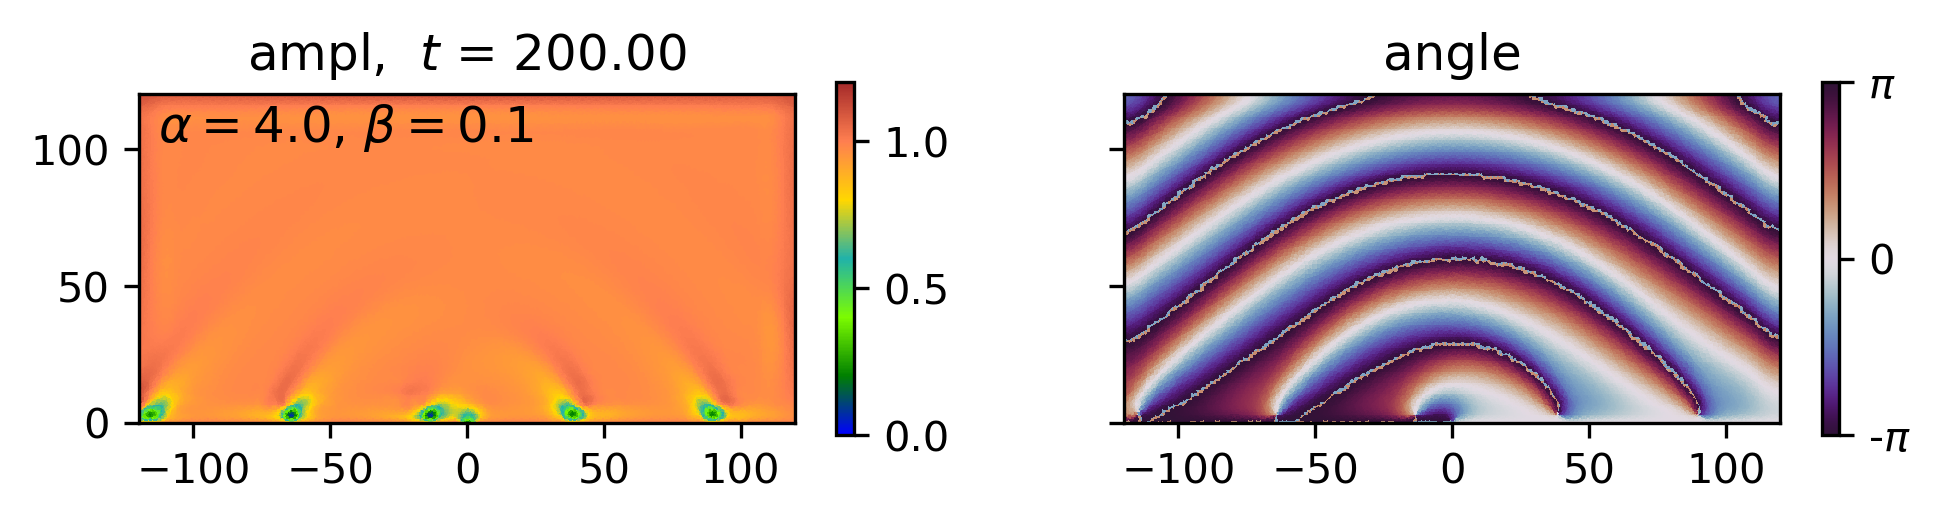

In [32]:
ofile = ofileroot + '_snap.png'
cgle.disp(mesh,gfu,time,ofile=ofile,draw_mesh=False,subdivn=2,figsize=[7,3],label=clabel,labelpos=[0.03,0.98],cbar_shrink=0.4) 
cgle.disp(mesh,gfu,time,ofile="",draw_mesh=False,subdivn=2,figsize=[7,3],label=clabel,labelpos=[0.03,0.98],cbar_shrink=0.4) 

craete bilinearformapplication
 249.950

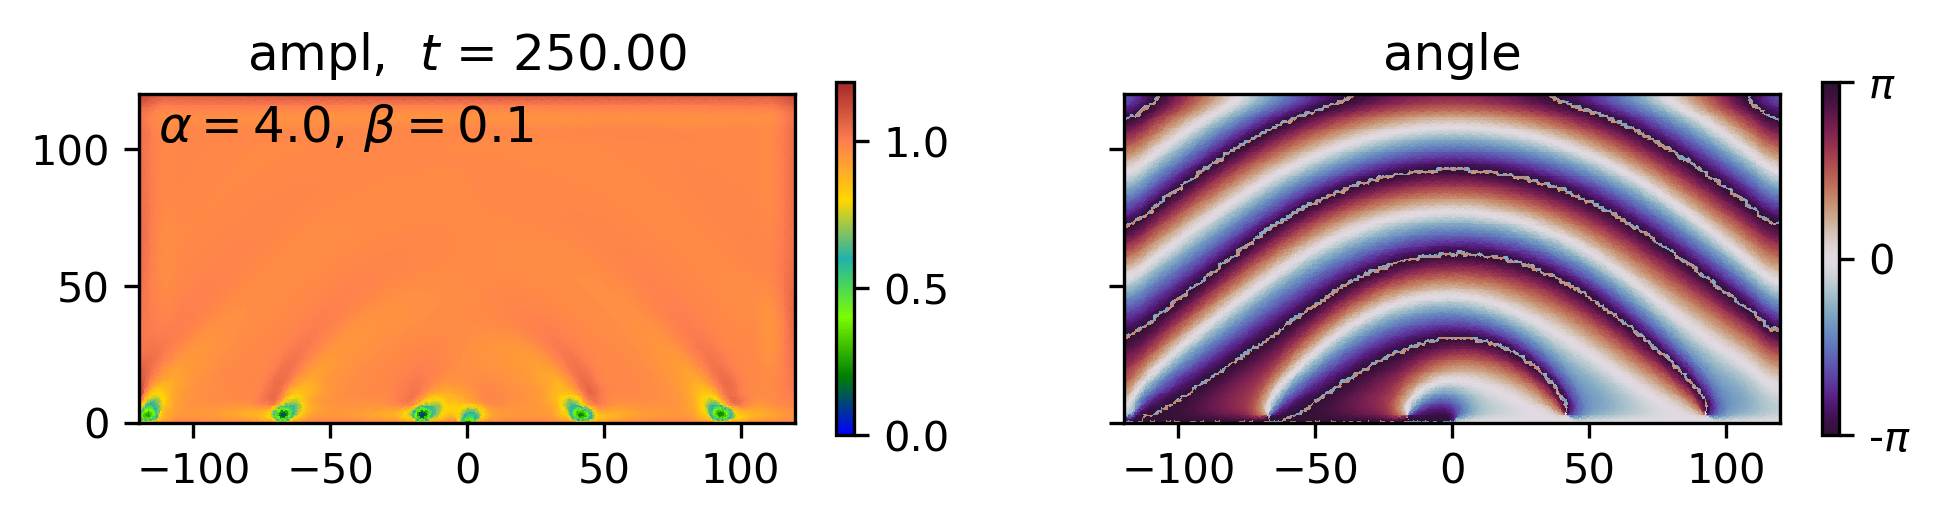

In [33]:
time= cgle.TimeStepping_CN(fes,gfu,scene,invastar, a_lap,minv,beta, dt, t0=time,tdur=50,nsamples = 50,gfun_op = True,uform='Aran',\
                       poutput=False,ofileroot=ofileroot,figparms=figparms)

ofile = ofileroot + '_snap2.png'
cgle.disp(mesh,gfu,time,ofile=ofile,draw_mesh=False,subdivn=2,figsize=[7,3],label=clabel,labelpos=[0.03,0.98],cbar_shrink=0.4) 
cgle.disp(mesh,gfu,time,ofile="",draw_mesh=False,subdivn=2,figsize=[7,3],label=clabel,labelpos=[0.03,0.98],cbar_shrink=0.4) 

In [8]:
def pa(label,avec):
    scale = 100.0/3.33
    lam_vert = avec[0]
    lam_hor = avec[1]
    dt = avec[3]
    alpha = avec[4]
    beta = avec[5]
    Ab = avec[6]
    period = avec[7]
    print(label+' lam_vert={:.1f}=lam_hor={:.1f} v={:.2f} alpha={:.1f} beta={:.1f} A_b={:.1f} period={:.1f}'.format(\
        lam_vert*scale, lam_hor*scale, avec[2]*scale/dt,alpha,beta,Ab,period))
    
# let's measure wavelengths and speeds for a1,a2,a3 simulations 
#   lam_vert, lam_hor, moved , in dt alpha, beta , A_b , period (units time)
#  scale 100 = 3.33  Scale is equivalent movies and snaps viewed in viewer 

a1 = np.array([1.23, 1.8, 2.5-1,141-118,4,  0.1,2,30]) # # alpha = 4, beta = 0.1 A_b = 2
pa('a1',a1)

a2 = np.array([1.2, 1.70, 2-1 , 189-164 , 2,0.1,2,40])  # alpha = 2, beta = 0.1 A_b = 2
pa('a2',a2)

a3 = np.array([1.1,1.80,2-1  ,110-96, 4 ,  0.1,1,23]) # alpha = 4, beta = 0.1 A_b = 1
pa('a3',a3)



a1 lam_vert=36.9=lam_hor=54.1 v=1.96 alpha=4.0 beta=0.1 A_b=2.0 period=30.0
a2 lam_vert=36.0=lam_hor=51.1 v=1.20 alpha=2.0 beta=0.1 A_b=2.0 period=25.0
a3 lam_vert=33.0=lam_hor=54.1 v=2.15 alpha=4.0 beta=0.1 A_b=1.0 period=40.0
